## Deconstructing a payment transaction

This is a Bitcoin transaction: <a href="https://mempool.space/tx/29a3efd3ef04f9153d47a990bd7b048a4b2d213daaa5fb8ed670fb85f13bdbcf" target="_blank" rel="noopener noreferrer">29a3efd3ef04f9153d47a990bd7b048a4b2d213daaa5fb8ed670fb85f13bdbcf</a>

This transaction was confirmed in block *153509* on 16 November 2011. It has 11 inputs and two outputs: 50,000 BTC and 500,000 BTC.. But I want to explore how this transaction is stored in the blockchain, and then read it's inputs without using services like mempool.


#### Getting the raw transaction data

`29a3efd3ef04f9153d47a990bd7b048a4b2d213daaa5fb8ed670fb85f13bdbcf` is the hash of the transaction data. But, to examine this transaction, I need to get the actual data bytes of this transaction. Because i'm running a pruned node, I need to request the block first from a full archived peer, and then request the transaction from the downloaded local block.

In [10]:
# $ bitcoin-cli getblockhash 153509
#   00000000000000fb62bbadc0a9dcda556925b2d0c1ad8634253ac2e83ab8382f

# $ bitcoin-cli getpeerinfo
#   Selected peer fields:
#   id: 25    network: ipv4    services: 0000000000000c09
#   servicesnames: NETWORK, WITNESS, NETWORK_LIMITED, UNKNOWN[2^11]

# $ bitcoin-cli getblockfrompeer \
#     00000000000000fb62bbadc0a9dcda556925b2d0c1ad8634253ac2e83ab8382f 25
#   {}

# $ bitcoin-cli getrawtransaction \
#     29a3efd3ef04f9153d47a990bd7b048a4b2d213daaa5fb8ed670fb85f13bdbcf \
#     0 \
#     00000000000000fb62bbadc0a9dcda556925b2d0c1ad8634253ac2e83ab8382f

In [19]:
raw_tx_hex = (
    "010000000b04a4abee8360f7a660bcf1c298496d927b6ad1f25dd12485e6a572"
    "e275cbd43f000000008b483045022100c6d59290df934bac08bc4124b06154ee"
    "21394d37ec958d145129a885dbd63eab0220036251120e4ceacc8e9ff1358504"
    "9945c7dbdb85921a6e077a80c7e410931f4a014104f3ce8948c592690cb36a7e"
    "6e31534927569f41e45c77fbdb95fdb0e235717a295b2a281c04619139c453dd"
    "9139e951086325b4021bd28da6fc3da86943cd04cfffffffff21fd91e6dd6483"
    "8eadce9bc0d687af571779c3af4b53bada845485466decf005000000008b4830"
    "4502205d309b632a816f1f2479b8ca284301fce3fc8f979306722bba4cf28c8f"
    "a7ed76022100a3313ee59bbf0e61e29302b2ea597a993a73e93be841f2f7dd3f"
    "6e9623572793014104ca3b25750307a483c0cff8efb1413c98b4e18765485d94"
    "eac147f21f507169997a72aeb50f0b01ed6b468c9554143125f63c0b2b229a59"
    "7e695718b86d711607ffffffff4dd6c46e3e68fc05243b6f894e2f3e4d2782d1"
    "c8a3d17b9a2c5e78912bbaf433010000008b483045022100f3f1d6c0e76a00e8"
    "9a5278fa14eae8de93454174199f72c98aef54dabb2074d10220172dc0d6958e"
    "fa8dc18c621f2d56fd0484ecb04e3d65e2284268916c1c324ade014104daeab6"
    "af397baf06fcc91b6c04a28ffb2cd80312e954a2a55f7c864094608032ef657e"
    "8296dfc2f86ecf28fe32925c0f648d3ef16b96934a34b29dd871ff057affffff"
    "ff52aabc7fdee0588d63fff3fc00e20b00a87cffa6a37aad7168741b1f0e77bd"
    "ff000000008b4830450220274a5a9577f0786fb17d373b6d1995a6cff752320b"
    "f4e3d5ee41b15fdd86ef2a022100fd1d0c0f43d05e479430c3c9bd5481f5be92"
    "9a7f2b82d14292ef192653c3b94c014104988828ea7144ff00def9988e88aad9"
    "8b1f22d01000fc4b52d1003c9b32de0534cff71c0a045098bb28f699bcc9db13"
    "533c0998eb2133085d37cac65b5bd74c1fffffffff5aab5581c575a56a803ef5"
    "d8698dc34014261d196ada1da3300731380d7e672d000000008b483045022016"
    "15a116a2e057f3f8f2a63340d0387b820a6f9d1067758f4f6cdec76c04951a02"
    "2100a1ada9e03a0d9603743d41347ffd992642544d6dfdc51121b7bf622e12cb"
    "1547014104830b3b139b0a8707f348840b0fa358164869fbc0c423a2785cb0a1"
    "8ff73517f8878cefd643e86e682eb93d07216f76993c9e980592de07c507c3a2"
    "659efff6aaffffffff74d7cd370a334aabee3b8328b67a63f1768583405e73eb"
    "d291dd86189983a61c000000008a4730440220432ff0f90a3f5372a8dc4b3d2e"
    "7165e110efa16b40784ea4d5ab866b736712ed02201a759b630d562f4dbc4a7d"
    "2fca406ad54e235564346bc360dec26d6e72bb60fa014104ca0bb72303672885"
    "ad953279309694c71574d50d2c6e1f5f1e7ab1b0bf3df67e5439b3f6e2501dda"
    "539812e414991ebaa547631374ce2bda9dd7211099886827ffffffff8941eb7f"
    "e688ff48357981c4756906e331c07f332429be5b2cfc7a945644f80f00000000"
    "8a47304402204e074678b525927a8f459d1dc93ad738ce02c0ea77c50a749647"
    "032eda662eee02203c1a98e9b116dc2fe9e7325a5696ad8e3ad26d2d10503e6e"
    "3209f4f5f40f6e34014104f9baa86b46b04f2a2dc4270903bcca9444026b7f18"
    "4d879f089462e332f260f6de8e05f08285a4a3c716220d9ec0f7e9fde354c779"
    "f32f00dd4d4cd8d4a1ac28ffffffff948be2e03f9537a35319e8cee2b7b9ed27"
    "69ca59734e5d4b42951ef7ba3bb4a8000000008b483045022100fcf1deaaa047"
    "e8f1b8b8ac783760ea5a0af15adbb9eed1c1748942a57510e27402204c278b12"
    "c4991480dc714af66395f5d8f42e411423bf27b024f62267c45a0d37014104cf"
    "d128c3f322b59c21d452d5c4c7b4d1a3237a2d31c6f4033b32db78c19cb342ff"
    "c151acc272a02a13ba985a523b655689d8118f502b8a7fb8df5fc7bd8458ceff"
    "ffffffb2cae04cf238b4d47c614da5ce9948f089a02f1ff3e22cda6b9f9196bd"
    "a87215010000008b483045022017a74373ef19756e275f2d987925a8bd22cfaf"
    "1c93eede7db63102dc73b7cfd0022100fd2f040d7d3ccd1a2188923f8c756025"
    "3aa2a910d8e9cd06a8a05fc69c12f6ce014104daeab6af397baf06fcc91b6c04"
    "a28ffb2cd80312e954a2a55f7c864094608032ef657e8296dfc2f86ecf28fe32"
    "925c0f648d3ef16b96934a34b29dd871ff057affffffffbe75c9f1faf79fb885"
    "018e3353ada4a7fb5c989bc26f031c5aee69d1eabad957000000008a47304402"
    "20360d35b0a98dd086d242f8976aa704b808541ad78ef5cba45e4eb73c1efbaa"
    "a7022025a3d981b9e0836a2493698b802bf7f0eae72de0252c7eac059ad14b1b"
    "27001b014104d969f0d456196f4c16945bc71fc460615002d1554fc8d774288a"
    "a8fc5c9eca1622a3dcb1e6a8314c94844e516c0543316b2e75d465c8fc2f0d0d"
    "20334e53f7dbffffffffbcbad95cac8bbe08538f7b12c240e96866358dfa819d"
    "e6e940bb60ce7fae5c3d000000008b483045022100d916990888d0d26246b8d6"
    "cb944b1e8ebd6a4cdb2965ff7e4430883eef02c4e102205693b96aa1d6e9335f"
    "3cb2986b7f3a03357959e989570d03a56ccdb18a8d7e6d0141040840a410ed7a"
    "fdc3e3fe3923ae388413bbd8a9089062403e0adce62212bccfe1f80400530121"
    "cfdba5b52f3e16397f1959b14a09089778afd5ff41f8a856980fffffffff0200"
    "5039278c0400001976a914f1c87a5e8ff7d14e74b858089bf771c94b1b6db488"
    "ac00203d88792d00001976a914dcdf2f9892bfa1cb086530354eab3ba078a2f0"
    "9088ac00000000"
)

raw_tx_bytes = bytes.fromhex(raw_tx_hex)
len(raw_tx_bytes)

2055

#### Understanding the data

The raw transaction data has the following format:
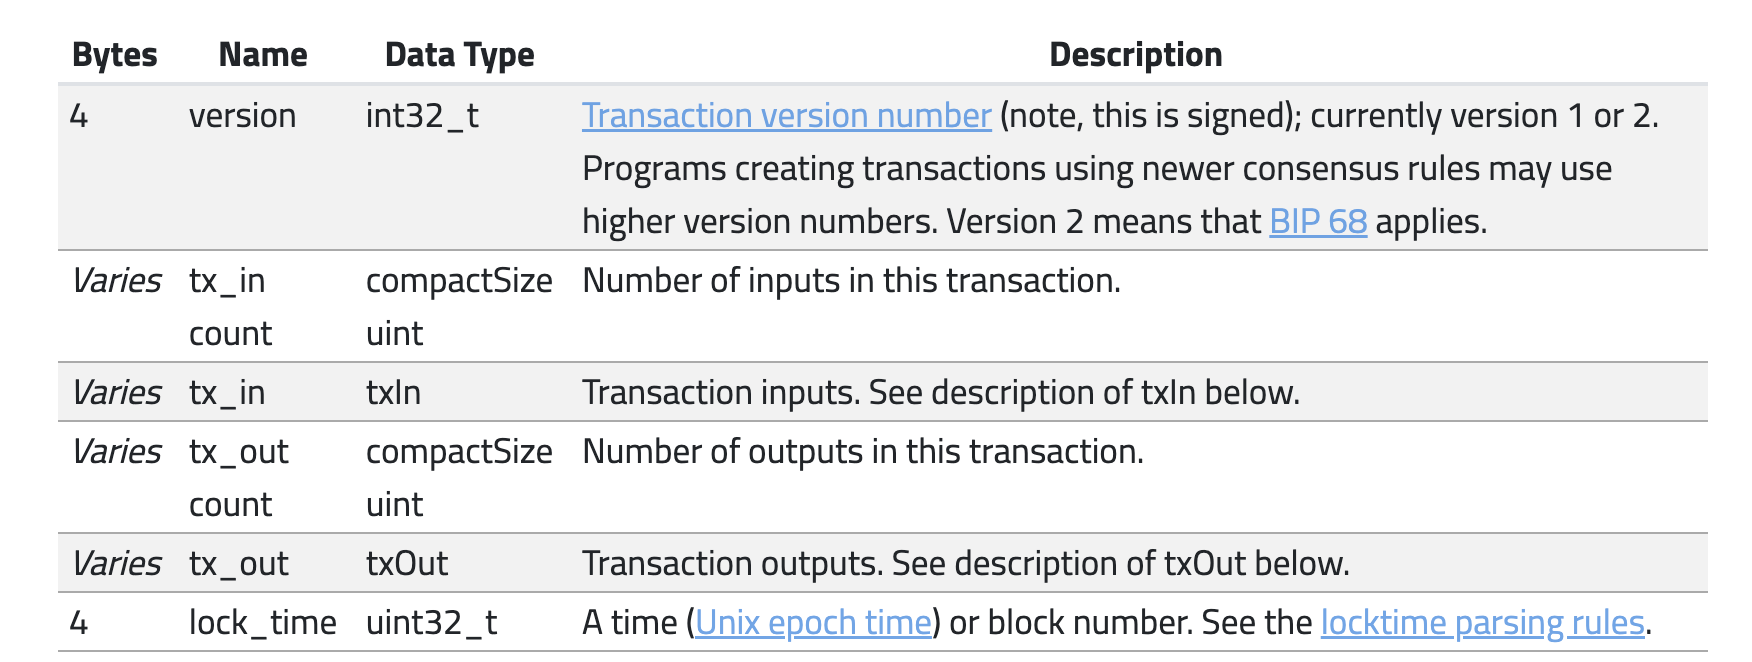
Pic taken from<a href="https://developer.bitcoin.org/reference/transactions.html#raw-transaction-format"> Bitcoin core.</a>